# 01 · Exploration

**Goal:** understand the data and find the main churn drivers before modeling.
The insights found here become the visuals of the dashboard's first page.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 50)

## 1. Raw data: structure and quality

In [2]:
raw = pd.read_csv(config.RAW_DATA)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as **text**. Some values are blank: these are brand-new customers (tenure = 0).

In [4]:
blank = raw["TotalCharges"].str.strip() == ""
print(f"Blank TotalCharges: {blank.sum()}")
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [5]:
print("Duplicated customers:", raw["customerID"].duplicated().sum())
print("Missing values:", raw.isna().sum().sum())

Duplicated customers: 0
Missing values: 0


## 2. Clean data (from `src/preprocess.py`)

In [6]:
df = pd.read_csv(config.CLEAN_DATA)
print(df.shape)
df[["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "Churn"]].describe().round(2)

(7043, 23)


,tenure,MonthlyCharges,TotalCharges,NumServices,Churn
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,4.15,0.27
std,24.56,30.09,2266.79,2.31,0.44
min,0.00,18.25,0.00,1.00,0.00
25%,9.00,35.50,398.55,2.00,0.00
50%,29.00,70.35,1394.55,4.00,0.00
75%,55.00,89.85,3786.60,6.00,1.00
max,72.00,118.75,8684.80,9.00,1.00


## 3. Target: how many customers churn?

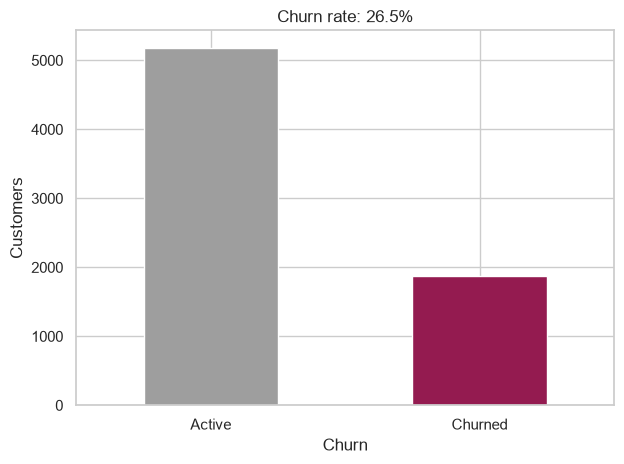

In [7]:
rate = df["Churn"].mean()
ax = df["Churn"].map({0: "Active", 1: "Churned"}).value_counts().plot.bar(color=["#9E9E9E", ACCENT], rot=0)
ax.set_title(f"Churn rate: {rate:.1%}")
ax.set_ylabel("Customers")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "01_churn_distribution.png", dpi=150); plt.show()

The classes are **imbalanced** (~26% churn). Consequence for modeling: accuracy is misleading,
because a model predicting "nobody churns" already reaches ~74%. We will use ROC-AUC and recall.

## 4. Churn rate by category

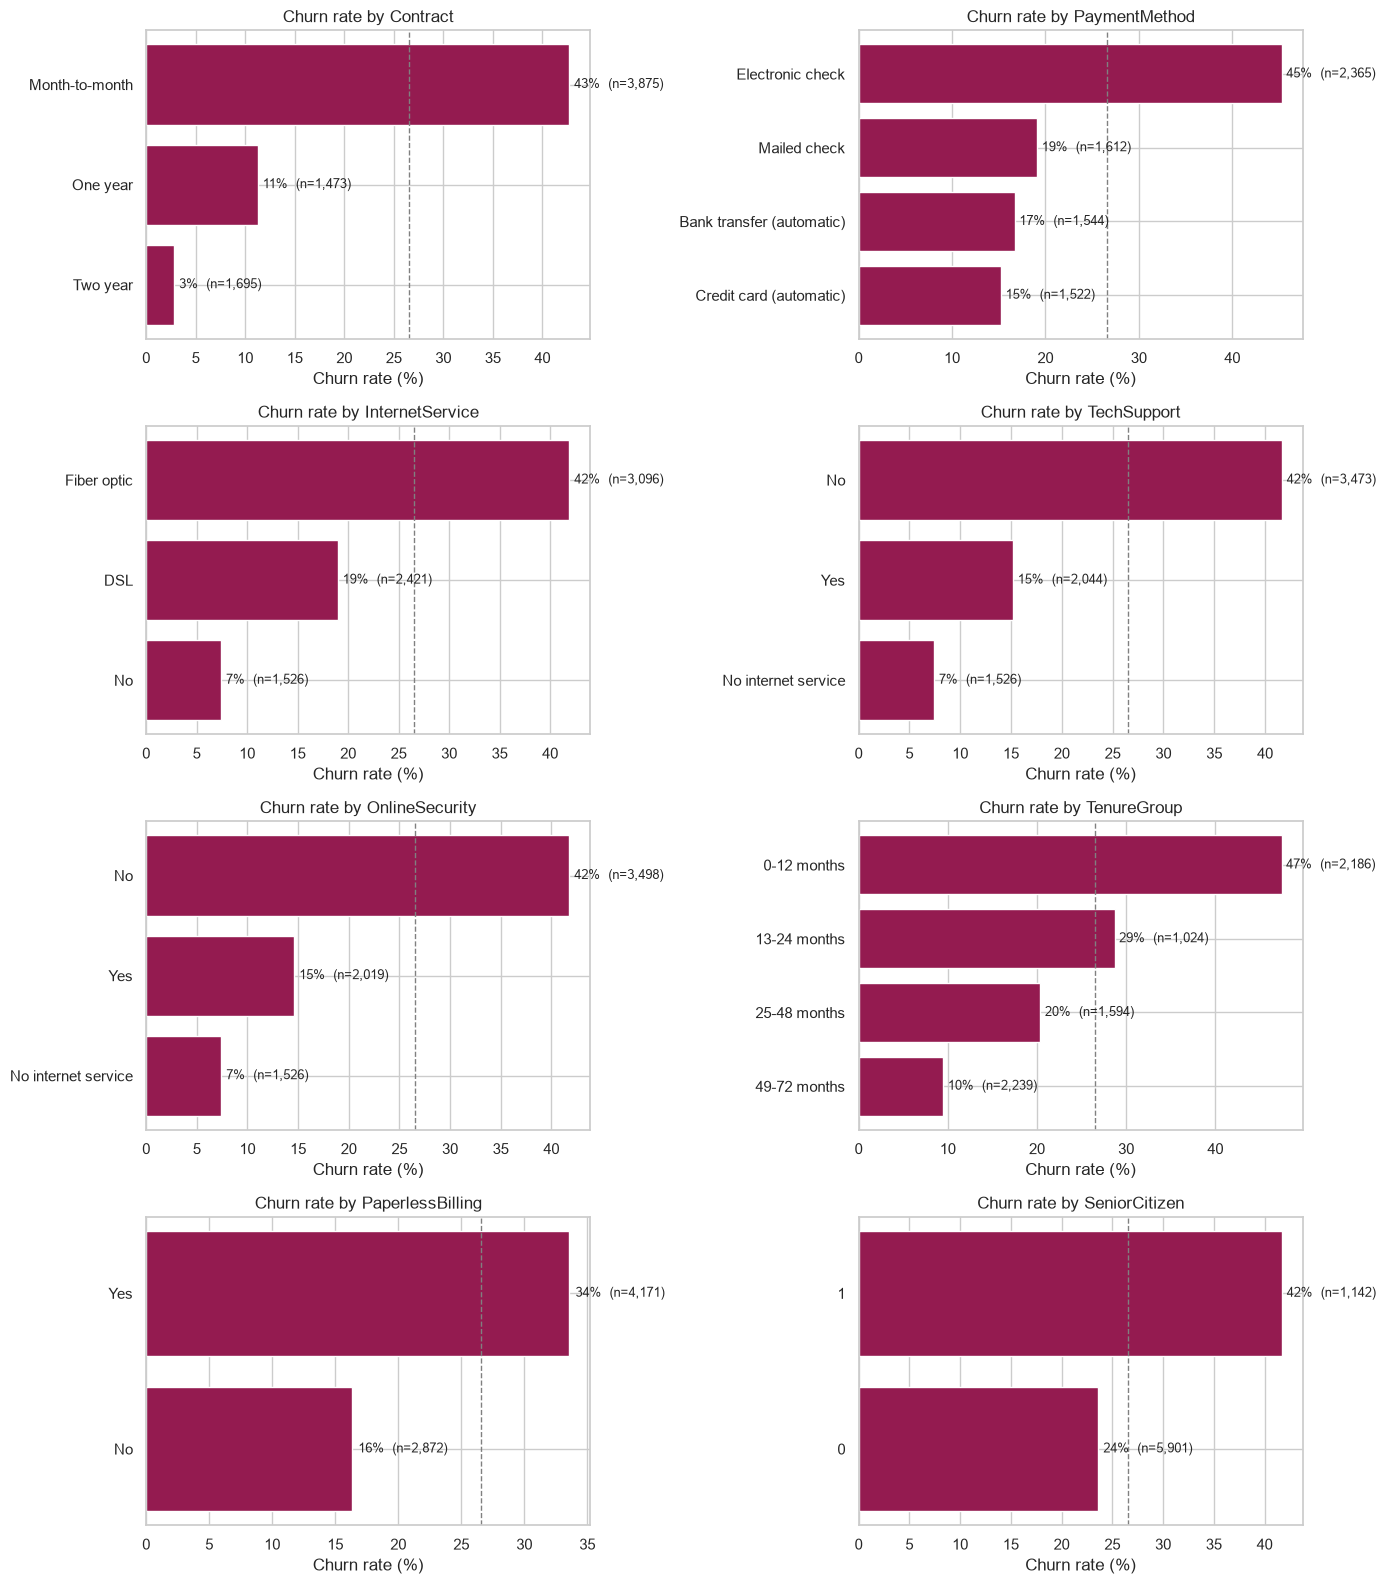

In [8]:
def churn_rate_by(col, ax=None):
    rates = df.groupby(col)["Churn"].agg(["mean", "size"]).sort_values("mean", ascending=False)
    ax = ax or plt.gca()
    ax.barh(rates.index.astype(str), rates["mean"] * 100, color=ACCENT)
    ax.invert_yaxis()
    ax.axvline(rate * 100, color="grey", linestyle="--", linewidth=1)
    for i, (m, n) in enumerate(zip(rates["mean"], rates["size"])):
        ax.text(m * 100 + 0.5, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=9)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate (%)")
    return rates

cols = ["Contract", "PaymentMethod", "InternetService", "TechSupport",
        "OnlineSecurity", "TenureGroup", "PaperlessBilling", "SeniorCitizen"]
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for col, ax in zip(cols, axes.ravel()):
    churn_rate_by(col, ax)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "01_churn_by_category.png", dpi=150); plt.show()

The dashed line is the overall churn rate. Bars far to the right of it are **risk factors**.

## 5. Numeric variables: churners vs. active customers

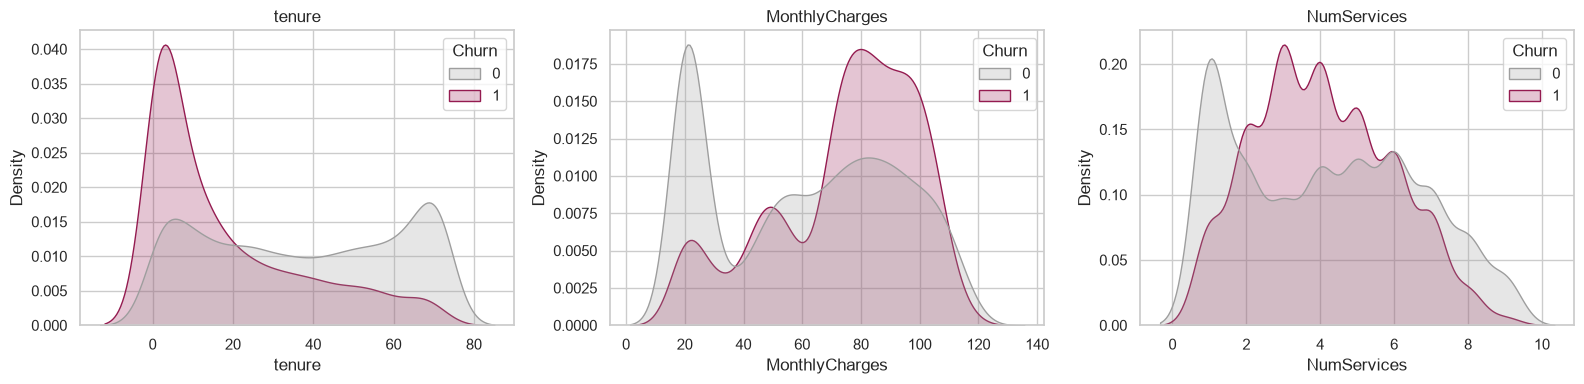

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for col, ax in zip(["tenure", "MonthlyCharges", "NumServices"], axes):
    sns.kdeplot(data=df, x=col, hue="Churn", common_norm=False, fill=True,
                palette={0: "#9E9E9E", 1: ACCENT}, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "01_numeric_distributions.png", dpi=150); plt.show()

In [10]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges", "NumServices"]].median().rename(index={0: "Active", 1: "Churned"})

,tenure,MonthlyCharges,TotalCharges,NumServices
Churn,,,,
Active,38.0,64.425,1679.525,4.0
Churned,10.0,79.650,703.550,4.0


## 6. Correlations between numeric variables

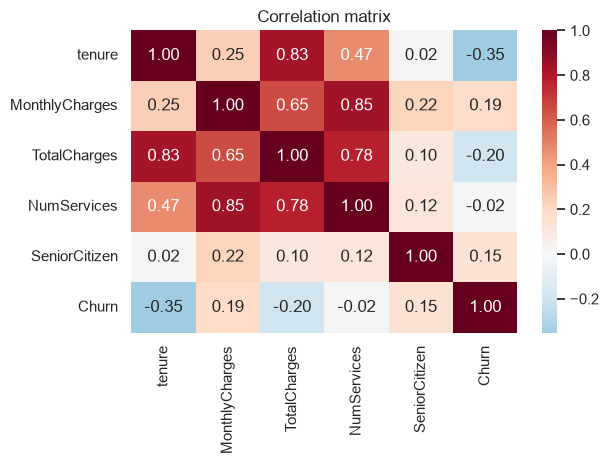

In [11]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "NumServices", "SeniorCitizen", "Churn"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "01_correlations.png", dpi=150); plt.show()

`TotalCharges` is strongly correlated with `tenure` (r = 0.83, it is roughly tenure × monthly charges).
Tree models handle this well; for logistic regression it adds redundancy.

## 7. Key insights

These numbers come from the outputs above. They go into the README and the dashboard.

1. **Contract:** month-to-month customers churn at **42.7%** vs **2.8%** for two-year contracts
   (11.3% for one-year). Contract length is the strongest churn driver.
2. **Tenure:** **47.4%** of customers in their first year churn, vs only 9.5% after 4 years
   (49–72 months). The first 12 months are the critical period for retention.
3. **Payment:** electronic check users churn at **45.3%**, about 3× more than automatic payment
   users (16.7% bank transfer, 15.2% credit card).
4. **Services:** customers without tech support / online security churn more
   (**41.6%** vs **15.2%** for tech support, **41.8%** vs **14.6%** for online security).
5. **Price:** churners pay a higher median monthly charge (**$79.65** vs **$64.43**) and have a much
   shorter median tenure (**10** vs **38** months).

**Other risk factors:** fiber optic (41.9%), senior citizens (41.7%) and paperless billing (33.6%)
are all above the overall churn rate of **26.5%**.

**Typical at-risk profile:** a new customer on a month-to-month contract, paying by electronic check,
with fiber optic and no protection services.